## Exploration Vs Exploitation
The exploration–exploitation dilemma is one of the fundamental challenges in deep reinforcement learning (RL). Agents must strike a trade-off between making decisions based on current beliefs or gathering more information.
If we have learned all the information about the environment, we are able to find the best strategy by even just simulating brute-force, let alone many other smart approaches. The dilemma comes from the incomplete information: we need to gather enough information to make best overall decisions while keeping the risk under control. With exploitation, we take advantage of the best option we know. With exploration, we take some risk to collect information about unknown options. The best long-term strategy may involve short-term sacrifices. For example, one exploration trial could be a total failure, but it warns us of not taking that action too often in the future. Thus, we want strategies that exploit what we think are the best actions so far, but still explore other actions. The exploration vs. exploitation tradeoff is often studied under more general
models such as MDPs.

## Multi-Armed Bandit
The multi-armed bandit (MAB) problem is a classic problem that well demonstrates the exploration vs exploitation dilemma. The MAB problem for a gambler is to decide which arm of a K-slot machine to pull to maximize his total reward in a series of trials. Many real-world learning and optimization problems can be modeled in this way.
In the k-armed bandit problem, each of the k actions has an expected or mean reward given that that action is selected; it's the value of that action. We denote the action selected on time step t as $A_t$, and the corresponding reward as $R_t$. The value then
of an arbitrary action a, denoted $q_*(a)$, is the expected reward given that a is selected:
\
    \begin{aligned}
    q_*(a) = \mathbb{E}[R_t | A_t = a]
    \end{aligned}
\
If we knew the value of each action, then it would be trivial to solve the k-armed bandit problem: we would always select the action with highest value. We assume that you do not know the action values with certainty, although you may have estimates. We denote the estimated value of action $a$ at time step $t$ as $Q_t(a)$. We would like $Q_t(a)$ to be close to $q_*(a)$.

## Bandit Strategies (Action-Value Methods)
**The ($\epsilon$)-Greedy Methods**    
 
The simplest action selection rule is to select one of the actions with the highest estimated value, that is, one of the greedy actions. If there is more than one greedy action, then a selection is made among them in some arbitrary way, perhaps randomly. We write this greedy action selection method as
\
\begin{aligned}
    A_t = argmaxQ_t(a)
    \end{aligned}
\
Greedy action selection always exploits current knowledge to maximize immediate reward; it spends no time at all sampling apparently inferior actions to see if they might really be better. A simple alternative is to behave greedily most of the time, but every once in a while, say with small probability $\epsilon$, instead select randomly from among all the actions with equal probability, independently of the action-value estimates. We call methods using this near-greedy action selection rule $\epsilon$-greedy methods.


We structure our code with a main ABC class (Base Bandit). Every algorithm represents a subclass that inherits from the main class. The environemnt structure represents the environment associated with each algorithm.

In [2]:
from MAB_Agents import *

In [3]:
from abc import ABC, abstractmethod

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import beta
from tqdm import trange

from environment import (
    BanditEnvironment,
    BernoulliBanditEnvironment,
    GaussianBanditEnvironment,
)

class Base_Bandit(ABC):
    # @k_arm: # of arms
    # @epsilon: probability for exploration in epsilon-greedy algorithm
    # @initial: initial estimation for each action
    # @step_size: constant step size for updating estimations
    # @sample_averages: if True, use sample averages to update estimations instead of constant step size

    def __init__(
        self,
        env: BanditEnvironment,
        epsilon=0.0,
        initial=0.0,
        step_size=0.1,
        sample_averages=False,
    ):
        self.env = env
        self.k = env.num_actions
        self.step_size = step_size
        self.sample_averages = sample_averages
        self.indices = np.arange(self.k)
        self.epsilon = epsilon
        self.initial = initial

        self.average_reward = 0
        self.time = 0
        # estimation for each action
        self.q_estimation = np.zeros(self.k) + self.initial
        # # of chosen times for each action
        self.action_count = np.zeros(self.k)

    def reset(self):
        # estimation for each action
        self.q_estimation = np.zeros(self.k) + self.initial
        # # of chosen times for each action
        self.action_count = np.zeros(self.k)
        self.time = 0
        self.average_reward = 0

    # get an action for this bandit
    @abstractmethod
    def act(self) -> int:
        pass

    # take an action, update estimation for this action
    def step(self, action):
        # generate the reward under N(real reward, 1)
        reward = self.env.get_reward(action)
        self.time += 1
        self.action_count[action] += 1
        self.average_reward += (reward - self.average_reward) / self.time

        if self.sample_averages:
            # update estimation using sample averages
            self.q_estimation[action] += (
                reward - self.q_estimation[action]
            ) / self.action_count[action]
        else:
            # update estimation with constant step size
            self.q_estimation[action] += self.step_size * (
                reward - self.q_estimation[action]
            )

        return reward

In [4]:
import random
from abc import ABC, abstractmethod

import numpy as np


class BanditEnvironment(ABC):
    """Abstract base class for bandit environments"""

    def __init__(self, num_actions: int):
        self._num_actions = num_actions
        self._best_action = None

    @abstractmethod
    def reset(self):
        pass

    @abstractmethod
    def get_reward(self, action) -> float:
        pass

    @property
    def best_action(self):
        return self._best_action

    @property
    def num_actions(self):
        return self._num_actions


class GaussianBanditEnvironment(BanditEnvironment):
    def __init__(self, num_actions: int = 10, true_reward: float = 0.0):
        super().__init__(num_actions)
        self.true_reward = true_reward
        self.q_true = np.random.randn(self.num_actions) + self.true_reward
        self._best_action = np.argmax(self.q_true)

    def reset(self):
        self.q_true = np.random.randn(self.num_actions) + self.true_reward
        self._best_action = np.argmax(self.q_true)

    def get_reward(self, action) -> float:
        return np.random.randn() + self.q_true[action]


class BernoulliBanditEnvironment(BanditEnvironment):
    def __init__(self, true_probs: list):
        super().__init__(len(true_probs))
        self.true_probs = np.array(true_probs)
        self._best_action = np.argmax(true_probs)

    def reset(self):
        pass

    def get_reward(self, action):
        return 1 if random.random() < self.true_probs[action] else 0

In [ ]:
class EpsilonGreedy(Base_Bandit):
    def act(self):
        if np.random.rand() < self.epsilon:
            return np.random.choice(self.indices)
        q_best = np.max(self.q_estimation)
        return np.random.choice(np.where(self.q_estimation == q_best)[0])

The upper figure compares a greedy method with two $\epsilon$-greedy methods ($\epsilon$=0.01 and $\epsilon$=0.1), on the 10-armed testbed. All the methods formed their action-value estimates using the sample-average technique. The upper graph shows the increase in expected reward with experience. The greedy method improved slightly faster than the other methods at the very beginning, but then leveled off at a lower level. It achieved a reward-per-step of only about 1, compared with the best possible of about 1.55 on this testbed. The greedy method performed significantly worse in the long run because it often got stuck performing suboptimal actions.   

The lower graph shows that the greedy method found the optimal action in only approximately one-third of the tasks. In the other two-thirds, its initial samples of the optimal action were disappointing, and it never returned to it. The $\epsilon$-greedy methods eventually performed better because they continued to explore and to improve their chances of recognizing the optimal action. The $\epsilon$ = 0.1 method explored more, and usually found the optimal action earlier, but it never selected that action more than 91% of the time. The $\epsilon$ = 0.01 method improved more slowly, but eventually would perform better than the $\epsilon$ = 0.1 method on both performance measures shown in the figure. It is also possible to reduce $\epsilon$ over time to try to get the best of both high and low values. 

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2000/2000 [00:26<00:00, 76.55it/s]


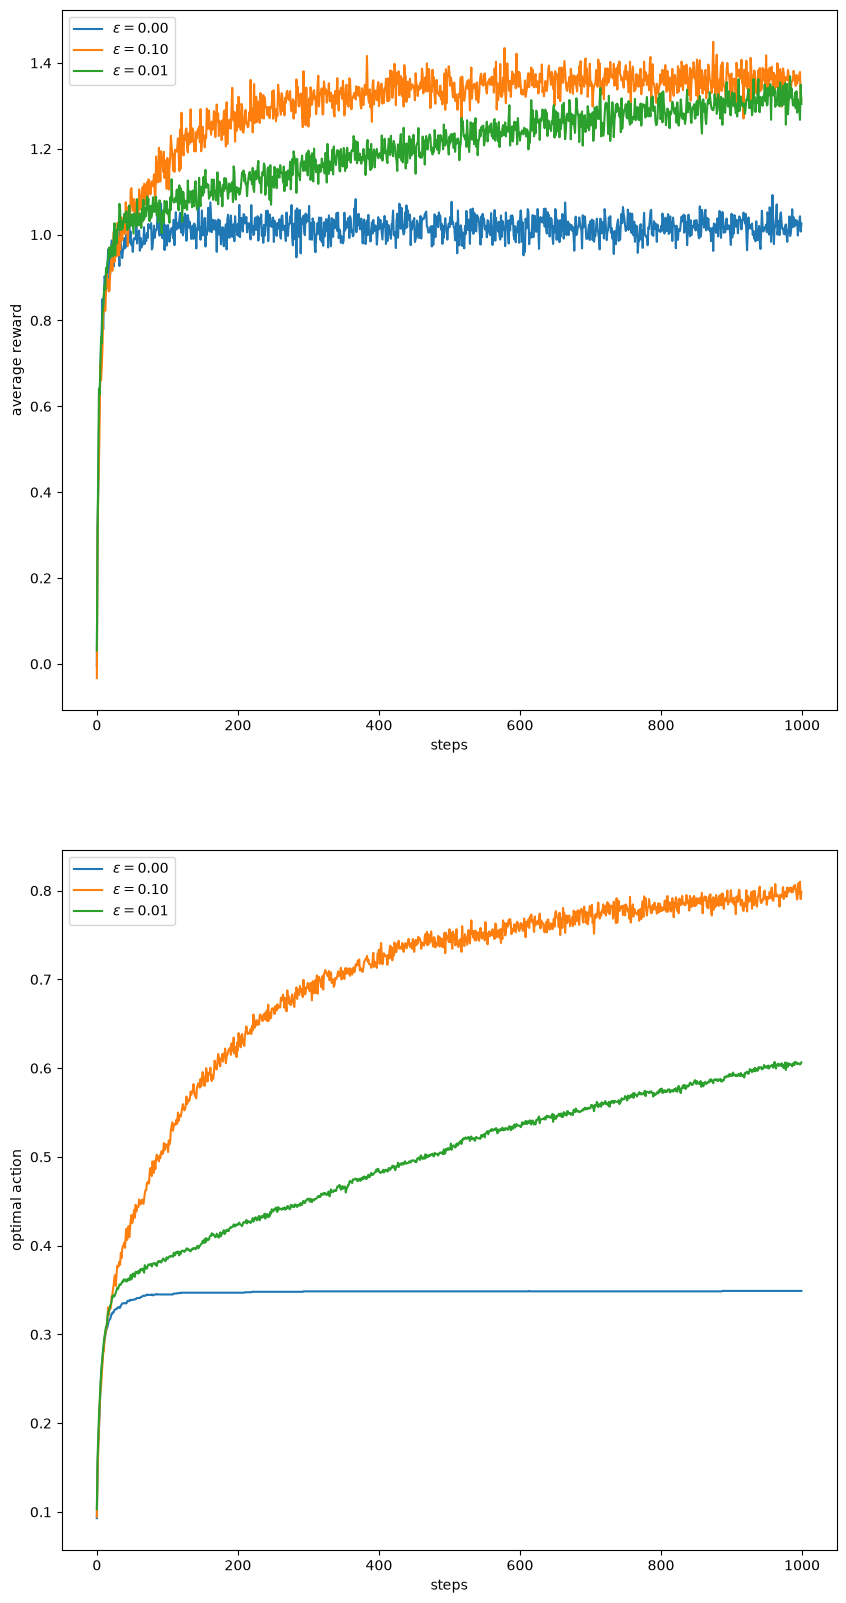

In [2]:
figure_epsilongreedy(show=True)

## Upper-Confidence-Bound Action Selection

Exploration is needed because there is always uncertainty about the accuracy of the action-value estimates. The greedy actions are those that look best at present, but some of the other actions may actually be better. $\epsilon$-greedy action selection forces the non-greedy
actions to be tried, but indiscriminately, with no preference for those that are nearly greedy or particularly uncertain. It would be better to select among the non-greedy actions according to their potential for actually being optimal, taking into account both how close their estimates are to being maximal and the uncertainties in those estimates. One effective way of doing this is to select actions according to:
$$
A_t \doteq \underset{a}{\arg\max} \left[ Q_t(a) + c \sqrt{\frac{\ln t}{N_t(a)}} \right],
$$
where ln t denotes the natural logarithm of t, $N_t(a)$ denotes the number of times that action a has been selected prior to time t, and the number c > 0 controls the degree of exploration. If Nt(a) = 0, then a is considered to be a maximizing action.
The idea of this upper confidence bound (UCB) action selection is that the square-root term is a measure of the uncertainty or variance in the estimate of a’s value. The quantity being max’ed over is thus a sort of upper bound on the possible true value of action a, with
c determining the confidence level. Each time a is selected the uncertainty is presumably reduced: $N_t(a)$ increments, and, as it appears in the denominator, the uncertainty term decreases. On the other hand, each time an action other than a is selected, t increases but Nt(a) does not; because t appears in the numerator, the uncertainty estimate increases. The use of the natural logarithm means that the increases get smaller over time, but are unbounded; all actions will eventually be selected, but actions with lower value estimates,
or that have already been selected frequently, will be selected with decreasing frequency over time.

In [ ]:
class UCB(Base_Bandit):
    def __init__(self, UCB_param=2, **kwargs):
        super().__init__(**kwargs)
        self.UCB_param = UCB_param

    def act(self) -> int:
        UCB_estimation = self.q_estimation + self.UCB_param * np.sqrt(
            np.log(self.time + 1) / (self.action_count + 1e-5)
        )
        q_best = np.max(UCB_estimation)
        return np.random.choice(np.where(UCB_estimation == q_best)[0])

Results with the UCB on the 10-armed testbed are shown in the figure below. The figure depicts average performance of UCB action selection on the 10-armed testbed. As shown, UCB often performs well, and it generally performs better than $\epsilon$-greedy action selection, except in the first k steps, when it selects randomly among the as-yet-untried actions.

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2000/2000 [00:24<00:00, 82.45it/s]


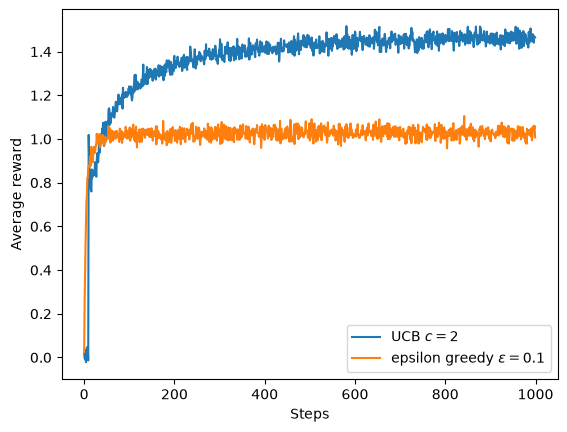

In [3]:
figure_UCB(show=True)

## Tomspon Sampling 

Thompson Sampling (TS)—also known as posterior sampling or probability matching—resolves the exploration-exploitation dilemma naturally through Bayesian inference. Rather than acting on point estimates, the agent maintains a posterior probability distribution over the unknown parameters $\theta$. At each step, the agent samples a plausible parameter vector from its current beliefs and selects the action that is optimal under that sampled model. Consequently, each action is selected with a probability equal to the posterior probability that it is the optimal action

## General Mathematical Formulation

Consider a general sequential decision problem:
* Let $\mathcal{X}$ be the set of feasible actions.
* Let $\theta$ denote the unknown parameter governing the system's reward distribution, with prior probability distribution $p(\theta)$.
* At time $t = 1, 2, \dots$, the agent selects an action $x_t \in \mathcal{X}$, observes an outcome $y_t$ drawn from likelihood $q_\theta(\cdot \mid x_t)$, and receives reward $r_t = r(y_t)$.
* Let $\mathbb{H}_{t-1} = \big((x_1, y_1), \dots, (x_{t-1}, y_{t-1})\big)$ denote the history of observations up to time $t-1$.

### Step 1: Posterior Sampling
At iteration $t$, the agent draws a random parameter sample $\hat{\theta}$ from the current posterior distribution $p_t(\theta) = \mathbb{P}(\theta \in \cdot \mid \mathbb{H}_{t-1})$:

$$
\hat{\theta} \sim p_t(\theta)
$$

### Step 2: Action Selection (Probability Matching)
Assuming the sampled parameter $\hat{\theta}$ represents the true environment, the agent chooses the action $x_t$ that maximizes expected reward:

$$
x_t = \underset{x \in \mathcal{X}}{\arg\max} \; \mathbb{E}_{q_{\hat{\theta}}}\big[r(y_t) \mid x_t = x\big]
$$

For discrete outcomes, this expectation is written as:

$$
\mathbb{E}_{q_{\hat{\theta}}}\big[r(y_t) \mid x_t = x\big] = \sum_{o} q_{\hat{\theta}}(o \mid x)\, r(o)
$$

Because $\hat{\theta}$ is drawn from the posterior distribution, the probability of choosing action $x^*$ matches the posterior probability that $x^*$ is truly optimal:

$$
\mathbb{P}(x_t = x^* \mid \mathbb{H}_{t-1}) = \mathbb{P}\!\left(x^* = \underset{x \in \mathcal{X}}{\arg\max} \; \mathbb{E}_{q_{\theta}}[r(y_t) \mid x_t = x] \;\middle\vert{}\; \mathbb{H}_{t-1}\right)
$$

### Step 3: Bayesian Posterior Update
After applying $x_t$ and observing outcome $y_t$, the agent updates its belief distribution via **Bayes' rule**:

$$
p_{t+1}(\theta) = \mathbb{P}_{p_t, q}(\theta \mid x_t, y_t) = \frac{p_t(\theta)\, q_\theta(y_t \mid x_t)}{\int p_t(u)\, q_u(y_t \mid x_t)\, du}
$$

*(For discrete parameter spaces, the integral in the denominator is replaced by a sum $\sum_v p_t(v) q_v(y_t \mid x_t)$.)*

---

## Canonical Case: The Beta-Bernoulli Bandit

In the **Bernoulli Bandit**, there are $K$ arms. Pulling arm $k \in \{1, \dots, K\}$ yields a binary reward $r_t \in \{0, 1\}$ with unknown success probability $\theta_k \in [0, 1]$:

$$
\mathbb{P}(r_t = 1 \mid x_t = k, \theta) = \theta_k, \qquad \mathbb{P}(r_t = 0 \mid x_t = k, \theta) = 1 - \theta_k
$$

### Prior Distribution
Because the **Beta distribution** is the conjugate prior for the Bernoulli likelihood, we model the prior belief over each arm's success probability $\theta_k$ independently using $\text{Beta}(\alpha_k, \beta_k)$ with probability density function:

$$
p(\theta_k) = \frac{\Gamma(\alpha_k + \beta_k)}{\Gamma(\alpha_k)\Gamma(\beta_k)} \, \theta_k^{\alpha_k - 1} (1 - \theta_k)^{\beta_k - 1}
$$

where $\Gamma(\cdot)$ is the gamma function. Setting $\alpha_k = \beta_k = 1$ yields a uniform prior $\text{Uniform}(0, 1)$. The mean of this distribution is $\mathbb{E}[\theta_k] = \frac{\alpha_k}{\alpha_k + \beta_k}$, and its variance shrinks as the pseudo-counts $\alpha_k + \beta_k$ grow.

### Algorithm Execution at Time $t$
1. **Sample from Posterior:** For each arm $k = 1, \dots, K$, draw a random success probability estimate:
   $$\hat{\theta}_k \sim \text{Beta}(\alpha_k, \beta_k)$$
2. **Select Action:** Pull the arm with the highest sampled value:
   $$x_t = \underset{k \in \{1, \dots, K\}}{\arg\max} \; \hat{\theta}_k$$
3. **Observe and Update:** Observe reward $r_t \in \{0, 1\}$ and update only the chosen arm's parameters:
   $$(\alpha_k, \beta_k) \leftarrow \begin{cases} (\alpha_k + r_t,\; \beta_k + 1 - r_t) & \text{if } x_t = k \\ (\alpha_k,\; \beta_k) & \text{if } x_t \neq k \end{cases}$$

---

## Performance Evaluation: Regret

The theoretical and empirical effectiveness of Thompson Sampling is measured using **regret**, which quantifies the reward lost by not always playing the optimal arm:

* **Per-Period Regret:** At time $t$, the expected difference between the optimal arm's mean reward and the selected arm's mean reward:
  $$\text{regret}_t(\theta) = \max_{k} \theta_k - \theta_{x_t}$$
* **Cumulative Regret:** The total expected regret accumulated over $T$ time steps:
  $$\text{Regret}(T) = \mathbb{E}\left[ \sum_{t=1}^{T} \left( \max_{k} \theta_k - \theta_{x_t} \right) \right]$$

As $t$ grows large, Thompson Sampling concentrates posterior probability mass onto the true optimal arm, causing per-period regret to decay toward zero and achieving optimal asymptotic logarithmic cumulative regret $\mathcal{O}(\ln T)$.


In [5]:
class ThompsonSampling(Base_Bandit):
    def __init__(
        self, env: BanditEnvironment, default_alpha=1, default_beta=1, **kwargs
    ):
        if not isinstance(env, BernoulliBanditEnvironment):
            raise TypeError(
                "ThompsonSampling requires a BernoulliBanditEnvironment instance."
            )
        # Thompson Sampling specific parameters
        self.default_alpha = default_alpha
        self.default_beta = default_beta

        # Call the superclass constructor with all remaining parameters
        super().__init__(env=env, **kwargs)

        # Initialize Thompson Sampling specific attributes using k from superclass
        self.alphas = [self.default_alpha] * self.k
        self.betas = [self.default_beta] * self.k
        self.successes = [0] * self.k
        self.failures = [0] * self.k

    def reset(self):
        super().reset()
        self.alphas = [self.default_alpha] * self.k
        self.betas = [self.default_beta] * self.k
        self.successes = [0] * self.k
        self.failures = [0] * self.k

    def act(self) -> int:
        samples = [np.random.beta(a, b) for a, b in zip(self.alphas, self.betas)]
        return int(np.argmax(samples))

    def step(self, action: int):
        """
        Simulates the environment: generates a reward based on true probabilities,
        updates the internal counts, and returns the reward.
        """
        reward = self.env.get_reward(action)
        self.time += 1
        self.action_count[action] += 1
        self.average_reward += (reward - self.average_reward) / self.time

        # update internal statistics
        if reward == 1:
            self.successes[action] += 1
            self.alphas[action] += 1
        else:
            self.failures[action] += 1
            self.betas[action] += 1

        return reward

    def plot_posteriors(self, arm_labels=None):
        # plots the Probability Density Function (PDF) of the Beta distribution for each arm."""
        n_arms = len(self.alphas)
        if arm_labels is None:
            arm_labels = [f"Arm {i + 1}" for i in range(n_arms)]

        x = np.linspace(0, 1, 1000)
        plt.figure(figsize=(10, 6))

        for i in range(n_arms):
            # calculate shape parameters: prior + observed
            a = self.alphas[i]  # equivalent to successes + prior_alpha
            b = self.betas[i]  # equivalent to failures + prior_beta

            pdf = beta.pdf(x, a, b)

            label = f"{arm_labels[i]} ($\\alpha$={a}, $\\beta$={b})"
            if i == self.env.best_action:
                plt.plot(x, pdf, label=label, linewidth=2.5, linestyle="--")
            else:
                plt.plot(x, pdf, label=label)

        plt.xlabel("Probability of Success ($\\theta$)")
        plt.ylabel("Probability Density")
        plt.title("Posterior Beta Distributions for Each Arm")
        plt.legend()
        plt.show()

The two figures illustrate how Thompson Sampling outperforms UCB (c = 2) on a 3-arm Bernoulli bandit problem with true success probabilities [0.2, 0.7, 0.5] and how the agent's posterior beliefs evolve over time. Together, the plots show probability matching in action. Because the High arm's posterior distribution sits almost entirely to the right of the other two curves, random samples $\hat{\theta}_k \sim \text{Beta}(\alpha_k, \beta_k)$ almost always favor the High arm while keeping just enough spread on uncertain arms to avoid getting stuck prematurely.

  0%|          | 0/2000 [00:00<?, ?it/s]

100%|██████████| 2000/2000 [00:43<00:00, 46.07it/s]


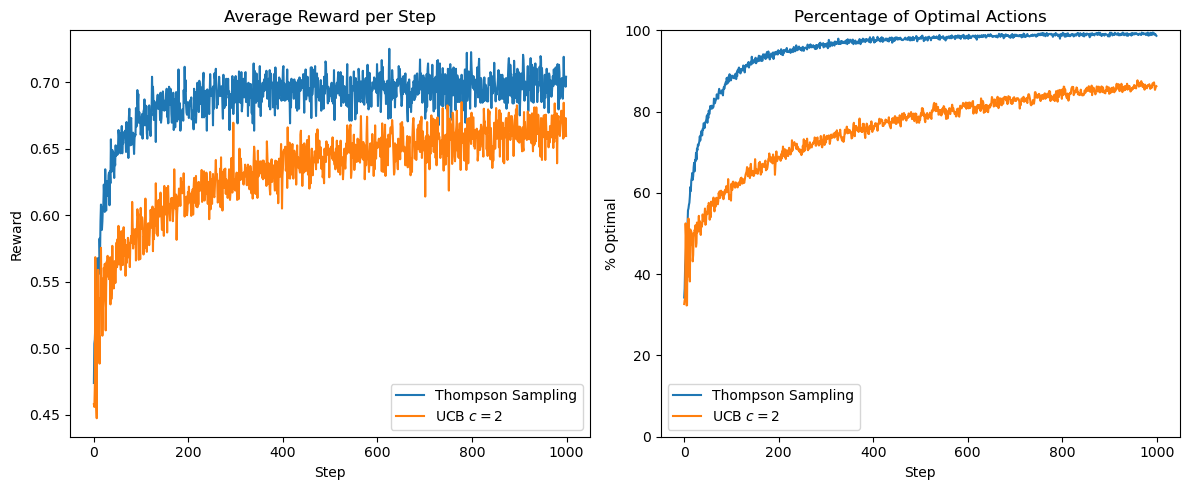

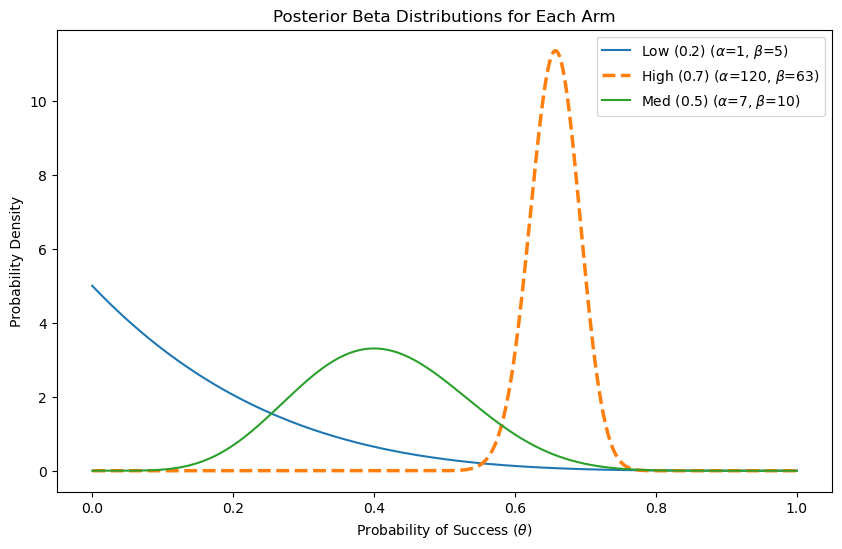

In [6]:
figure_TS(show=True)